<a href="https://colab.research.google.com/github/seungmin517/nuclei-detection-under-blur/blob/main/yim_nuclei_mini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 흐려지는 현미경 사진에서 세포핵 찾기: 1주 미니 실험

**질문.** 조직 깊은 곳을 찍을수록 현미경 사진은 흐려지고 어두워집니다. 그럴 때 세포핵을 찾는 AI는 **얼마나, 어디서 무너지고**, 흐린 사진을 섞어 학습시키면 **버틸 수 있을까요?**

점자 표지판 검수기(점검)에서 작은 점자 점을 YOLO로 찾았던 방법을 세포핵에 그대로 옮겨, 네 가지 방법을 같은 기준으로 비교합니다.

| 방법 | 내용 |
|---|---|
| A | 고전 영상처리 (Otsu 임계값 + watershed). AI 없음 |
| B | Cellpose `nuclei` (남이 학습해 둔 세포 분할 모델, 그대로 사용) |
| C | YOLO 미세조정 (점검과 같은 방식) |
| D | YOLO + 흐린·어두운 사진을 섞어 학습 |

**일정 (하루 2~3시간)**

| 날 | 할 일 | 남길 것 |
|---|---|---|
| 1일차 | 0~3번 실행: 데이터, 채점 방법, 방법 A | 흐림 단계 미리보기 그림, A의 점수 |
| 2일차 | 4~5번: Cellpose, YOLO 학습(C) | 학습 곡선 |
| 3일차 | 6번: 흐린 사진을 섞은 학습(D) | 학습 곡선 |
| 4일차 | 7~8번: 흐림·잡음 실험과 그래프 | 결과 표, 그래프 4장 |
| 5일차 | 9~10번: 숫자 정리, GitHub 업로드 | 지원서에 옮길 숫자 |

**런타임 > 런타임 유형 변경 > T4 GPU**로 바꾼 뒤 위에서부터 실행하세요. 결과는 Google Drive의 `yim_nuclei` 폴더에 저장되므로, 연결이 끊겨도 이미 끝난 단계는 다시 돌리지 않습니다.

> 이 노트북의 코드는 AI(Claude)와 함께 작성했습니다. 면접에서 설명할 수 있도록 각 단계가 **무엇을 왜 하는지**는 직접 이해해 두세요. 에러가 나면 화면을 캡처해 두세요. 고친 과정이 그대로 연구 경험입니다.

## 0. 설정

In [1]:
QUICK = False      # True: 적은 데이터로 전체 흐름만 빠르게 확인 (숫자는 의미 없음)
USE_DRIVE = True   # 결과를 Google Drive에 저장

import os, sys, subprocess
if os.environ.get('YIM_QUICK') == '1':
    QUICK = True
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    pip = [sys.executable, '-m', 'pip', 'install', '-q']
    subprocess.run(pip + ['ultralytics', 'fastremap', 'imagecodecs', 'roifile', 'fill-voids', 'natsort', 'tqdm'], check=True)
    # Cellpose 3은 numpy를 옛 버전으로 바꾸려 해서, 의존성 없이 설치하고 Colab의 numpy를 그대로 씁니다
    subprocess.run(pip + ['--no-deps', 'cellpose==3.1.1.3'], check=True)
    if USE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive/yim_nuclei' if (IN_COLAB and USE_DRIVE) else os.path.abspath(os.environ.get('YIM_ROOT', 'yim_nuclei'))
if QUICK:
    ROOT += '_quick'
for sub in ('runs', 'results', 'figures'):
    os.makedirs(f'{ROOT}/{sub}', exist_ok=True)
# 원본 사진(작은 파일 수만 개)은 Drive가 아닌 Colab 로컬 디스크에 둡니다. 연결이 끊기면 1~2분 안에 다시 받습니다
DATA = '/content/yim_data' if IN_COLAB else f'{ROOT}/data'
os.makedirs(DATA, exist_ok=True)

import torch
GPU = torch.cuda.is_available()
print('저장 위치:', ROOT)
print('GPU:', torch.cuda.get_device_name(0) if GPU else '없음 (런타임 유형을 T4 GPU로 바꾸세요)')

Mounted at /content/drive
저장 위치: /content/drive/MyDrive/yim_nuclei
GPU: 없음 (런타임 유형을 T4 GPU로 바꾸세요)


In [2]:
import glob, json, random, hashlib, shutil
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage.filters import threshold_otsu
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from skimage.measure import label, regionprops

SEED = 0
random.seed(SEED); np.random.seed(SEED)

# 흐림·잡음 단계 (0 = 원본). 깊은 조직 영상의 '흐려짐'과 '신호 약화 + 잡음'을 단순하게 흉내 낸 것
LEVELS   = [0, 1, 2, 3, 4, 5]
BLUR     = [0, 1, 2, 3, 4, 6]               # 가우시안 흐림의 시그마 (픽셀)
CONTRAST = [1, .8, .6, .45, .3, .2]         # 배경 대비 신호 세기
NOISE    = [0, 4, 8, 12, 16, 20]            # 잡음 표준편차 (0~255 기준)

IMGSZ   = 320 if QUICK else 640
EPOCHS  = 2 if QUICK else 60
BATCH   = 8 if QUICK else 16
CONF    = 0.25
BASE_WEIGHTS = 'yolo11n.pt'
METHOD_NAMES = {'A_classical': 'A classical', 'B_cellpose': 'B Cellpose',
                'C_yolo': 'C YOLO', 'D_yolo_aug': 'D YOLO + degraded training'}

## 1. 데이터: 2018 Data Science Bowl 세포핵 사진

Kaggle 2018 Data Science Bowl의 학습용 현미경 사진(공식 명칭 BBBC038)에서, 정답 마스크의 오류를 고친 공개 버전(`lopuhin/kaggle-dsbowl-2018-dataset-fixes`, CC0)을 씁니다. 사진마다 세포핵 하나하나의 마스크가 들어 있습니다.

- 사진은 형광, 명시야, 조직 염색(H&E 등) 세 종류가 섞여 있습니다. 종류별 성능도 따로 봅니다.
- 학습용 80%, 평가용 20%로 나눕니다(무작위, 시드 고정). 평가용 사진은 어떤 학습에도 쓰지 않습니다.

In [3]:
SRC = f'{DATA}/dsb'
if not os.path.exists(f'{SRC}/stage1_train'):
    subprocess.run(['git', 'clone', '--depth', '1', '-q',
                    'https://github.com/lopuhin/kaggle-dsbowl-2018-dataset-fixes', SRC], check=True)
TRAIN_DIR = f'{SRC}/stage1_train'
ids = sorted(os.listdir(TRAIN_DIR))
print('사진 수:', len(ids))

def load_img(i):                       # BGR uint8 (알파 채널은 버림)
    return cv2.imread(f'{TRAIN_DIR}/{i}/images/{i}.png', cv2.IMREAD_COLOR)

def image_type(bgr):
    b, g, r = (bgr[..., k].astype(np.float32) for k in range(3))
    if (np.abs(r - g).mean() + np.abs(g - b).mean()) > 6:
        return 'histology'
    return 'fluorescence' if np.median(bgr) < 100 else 'brightfield'

split_csv = f'{ROOT}/results/split.csv'
if os.path.exists(split_csv):
    split = pd.read_csv(split_csv)
else:
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(ids))
    n_val = round(len(ids) * 0.2)
    is_val = np.zeros(len(ids), bool); is_val[perm[:n_val]] = True
    split = pd.DataFrame({'id': ids, 'split': np.where(is_val, 'val', 'train'),
                          'type': [image_type(load_img(i)) for i in ids]})
    split.to_csv(split_csv, index=False)

train_ids = split.query("split == 'train'").id.tolist()
val_ids   = split.query("split == 'val'").id.tolist()
if QUICK:
    train_ids, val_ids = train_ids[:40], val_ids[:15]
TYPE = dict(zip(split.id, split.type))
print('학습', len(train_ids), '/ 평가', len(val_ids))
print(split.groupby(['split', 'type']).size().unstack(fill_value=0))

사진 수: 664
학습 531 / 평가 133
type   brightfield  fluorescence  histology
split                                      
train           11           432         88
val              5           109         19


In [4]:
# 정답 상자: 세포핵 마스크마다 감싸는 사각형 (x1, y1, x2, y2)
gt_path = f'{DATA}/gt_boxes.npz'
if os.path.exists(gt_path):
    GT = dict(np.load(gt_path))
else:
    GT = {}
    for i in ids:
        boxes = []
        for m in sorted(glob.glob(f'{TRAIN_DIR}/{i}/masks/*.png')):
            ys, xs = np.nonzero(cv2.imread(m, cv2.IMREAD_GRAYSCALE))
            if len(xs):
                boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
        GT[i] = np.array(boxes, np.float32).reshape(-1, 4)
    np.savez_compressed(gt_path, **GT)
n_nuclei = np.array([len(GT[i]) for i in val_ids])
print(f'평가용 사진 한 장의 세포핵 수: 중앙값 {np.median(n_nuclei):.0f}, 최대 {n_nuclei.max()}')

평가용 사진 한 장의 세포핵 수: 중앙값 28, 최대 199


## 2. 채점 방법과 흐림·잡음 만들기

**채점.** 예측 상자와 정답 상자가 절반 이상 겹치면(IoU ≥ 0.5) 맞힌 것으로 봅니다. 한 정답에는 예측 하나만 짝지읍니다(헝가리안 매칭).
- 정밀도 = 맞힌 수 / 예측 수, 재현율 = 맞힌 수 / 정답 수, **F1** = 둘의 조화평균
- **개수 오차** = |예측한 세포핵 수 − 실제 수| / 실제 수. 세포를 세는 실험에서는 이 값이 직접 쓰입니다.

**흐림·잡음.** 두 가지를 따로 바꿔 어떤 쪽이 더 치명적인지 봅니다.
- `blur`: 가우시안 흐림. 빛이 조직에서 산란되어 번지는 것을 흉내 냅니다.
- `noise`: 신호를 배경 쪽으로 약하게 만든 뒤 잡음을 더합니다. 깊을수록 빛이 덜 돌아오는 것을 흉내 냅니다.

실제 조직 광학을 계산한 것은 아니므로, 결과는 "단순한 열화 모형에서"라는 단서를 달아 말해야 합니다.

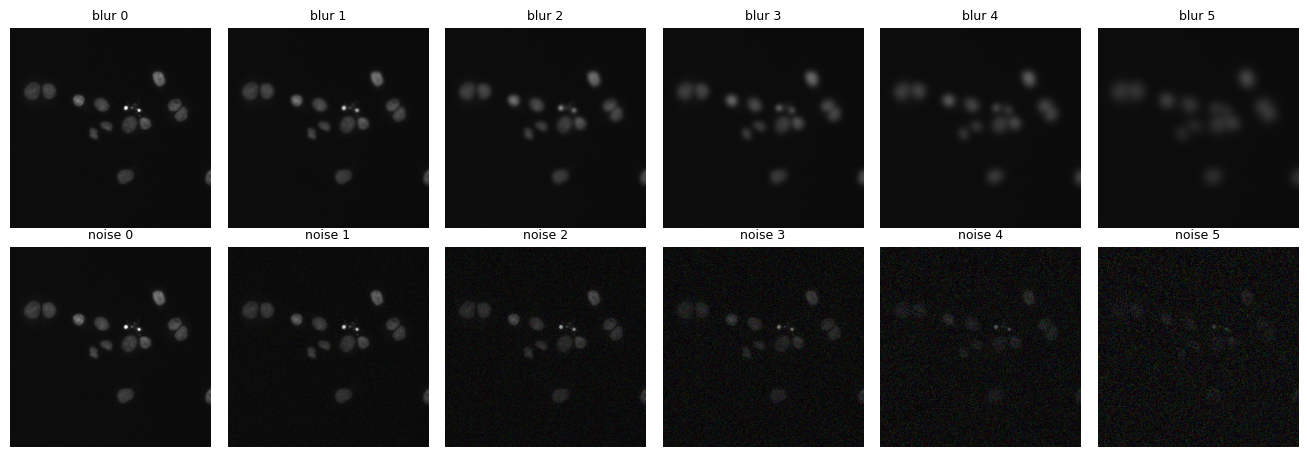

In [5]:
def iou_matrix(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def match(pred, gt, thr=0.5):
    # 맞힌 수, 틀린 예측 수, 놓친 정답 수
    if len(pred) == 0 or len(gt) == 0:
        return 0, len(pred), len(gt)
    iou = iou_matrix(pred, gt)
    r, c = linear_sum_assignment(-iou)
    tp = int((iou[r, c] >= thr).sum())
    return tp, len(pred) - tp, len(gt) - tp

def summarize(d):
    tp, fp, fn = d.tp.sum(), d.fp.sum(), d.fn.sum()
    p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
    return pd.Series({'F1': 2 * p * r / max(p + r, 1e-9), 'precision': p, 'recall': r,
                      'count_err': (abs(d.n_pred - d.n_gt) / d.n_gt.clip(lower=1)).mean()})

def degrade(bgr, kind, level, key=''):
    if level == 0:
        return bgr
    out = bgr.astype(np.float32)
    if kind == 'blur':
        out = cv2.GaussianBlur(out, (0, 0), BLUR[level])
    else:
        bg = np.median(out, axis=(0, 1), keepdims=True)
        out = bg + (out - bg) * CONTRAST[level]
        seed = int(hashlib.md5(f'{key}{level}'.encode()).hexdigest()[:8], 16)
        out += np.random.default_rng(seed).normal(0, NOISE[level], out.shape)
    return np.clip(out, 0, 255).astype(np.uint8)

# 미리보기: 같은 사진이 단계별로 어떻게 변하는지
demo = next(i for i in val_ids if TYPE[i] == 'fluorescence')
fig, ax = plt.subplots(2, len(LEVELS), figsize=(2.2 * len(LEVELS), 4.6))
for row, kind in enumerate(('blur', 'noise')):
    for col, lv in enumerate(LEVELS):
        ax[row, col].imshow(degrade(load_img(demo), kind, lv, demo)[..., ::-1]); ax[row, col].axis('off')
        ax[row, col].set_title(f'{kind} {lv}', fontsize=9)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/0_degradation_levels.png', dpi=150); plt.show()

## 3. 방법 A: 고전 영상처리

AI 없이 밝기만으로 찾습니다. 세포핵이 배경보다 밝도록 맞춘 뒤(명시야·염색 사진은 반전), Otsu 방법으로 임계값을 정하고, 붙어 있는 세포핵은 watershed로 나눕니다. **AI가 정말 필요한지 보여 주는 기준선**입니다.

In [6]:
def nuclei_bright_gray(bgr):
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    return 255 - g if np.median(g) > 127 else g      # 밝은 배경이면 반전

def boxes_from_labels(lab, min_area=15):
    return np.array([[p.bbox[1], p.bbox[0], p.bbox[3], p.bbox[2]]
                     for p in regionprops(lab) if p.area >= min_area], np.float32).reshape(-1, 4)

def classical_one(bgr):
    g = cv2.GaussianBlur(nuclei_bright_gray(bgr), (0, 0), 1)
    if g.max() == g.min():
        return np.zeros((0, 4), np.float32)
    fg = g > threshold_otsu(g)
    lab = label(fg)
    fg = (np.bincount(lab.ravel()) >= 15)[lab] & fg      # 15픽셀보다 작은 얼룩은 버림
    if not fg.any():
        return np.zeros((0, 4), np.float32)
    dist = ndi.distance_transform_edt(fg)
    peaks = peak_local_max(dist, min_distance=5, labels=label(fg), exclude_border=False)
    markers = np.zeros(dist.shape, np.int32)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
    return boxes_from_labels(watershed(-dist, markers, mask=fg))

def run_classical(imgs):
    return [classical_one(im) for im in imgs]

rows = [dict(zip(('tp', 'fp', 'fn'), match(p, GT[i])), n_pred=len(p), n_gt=len(GT[i]))
        for i, p in zip(val_ids, run_classical([load_img(i) for i in val_ids]))]
print('방법 A, 원본 사진:'); print(summarize(pd.DataFrame(rows)).round(3))

방법 A, 원본 사진:
F1           0.652
precision    0.603
recall       0.710
count_err    0.239
dtype: float64


## 4. 방법 B: Cellpose

Cellpose는 세포 분할에 널리 쓰이는 공개 모델입니다. 여기서는 세포핵용 `nuclei` 모델을 **추가 학습 없이** 그대로 씁니다. 세포핵 크기는 모델이 사진마다 스스로 추정합니다(`diameter=None`). 결과 마스크를 상자로 바꿔 다른 방법과 같은 기준으로 채점합니다.

In [7]:
try:
    from cellpose import models as cp_models
    CP = cp_models.Cellpose(gpu=GPU, model_type='nuclei')
    HAS_CP = True
except Exception as e:             # 설치나 모델 내려받기가 실패해도 나머지 실험은 계속합니다
    HAS_CP = False
    print('Cellpose를 불러오지 못해 방법 B는 건너뜁니다. 이 메시지를 캡처해 두세요:\n', repr(e)[:500])

import logging, warnings
logging.getLogger('cellpose').setLevel(logging.ERROR)     # 세포핵을 못 찾은 사진마다 뜨는 경고를 숨김

def run_cellpose(imgs):
    grays = [nuclei_bright_gray(im) for im in imgs]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        masks, *_ = CP.eval(grays, diameter=None, channels=[0, 0])
    return [boxes_from_labels(m.astype(np.int32)) for m in masks]

if HAS_CP:
    rows = [dict(zip(('tp', 'fp', 'fn'), match(p, GT[i])), n_pred=len(p), n_gt=len(GT[i]))
            for i, p in zip(val_ids, run_cellpose([load_img(i) for i in val_ids]))]
    print('방법 B, 원본 사진:'); print(summarize(pd.DataFrame(rows)).round(3))

100%|██████████| 25.3M/25.3M [00:00<00:00, 39.8MB/s]
100%|██████████| 3.54k/3.54k [00:00<00:00, 5.89MB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:365: FutureWarning: `torch.jit.script_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/cellpose/dynamics.py:760: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


방법 B, 원본 사진:
F1           0.886
precision    0.944
recall       0.834
count_err    0.184
dtype: float64


## 5. 방법 C: YOLO 미세조정

점검에서 점자 칸을 찾던 것과 같은 방식입니다. 세포핵 하나를 물체 하나로 보고, 일반 사물로 학습된 `yolo11n`에서 출발해 세포핵 사진으로 추가 학습합니다.

점검과 다른 점: 점자는 좌우로 뒤집으면 다른 글자가 되어 뒤집기 증강을 껐지만, **세포핵은 뒤집어도 세포핵**이라 기본 증강을 그대로 씁니다. 한 사진에 세포핵이 수백 개일 수 있어 `max_det=1000`으로 올립니다. T4 GPU에서 학습에 약 15~20분 걸립니다.

In [8]:
def write_yolo_split(name, split_ids, aug=False):
    # YOLO 형식 데이터 폴더. aug=True면 사진마다 흐리거나 어둡게 만든 사본을 하나씩 추가
    for sub in ('images', 'labels'):
        os.makedirs(f'{DATA}/{name}/{sub}', exist_ok=True)
    rng = np.random.default_rng(SEED)
    for i in split_ids:
        img = load_img(i); h, w = img.shape[:2]; b = GT[i]
        lines = [f'0 {(x1 + x2) / 2 / w:.6f} {(y1 + y2) / 2 / h:.6f} {(x2 - x1) / w:.6f} {(y2 - y1) / h:.6f}'
                 for x1, y1, x2, y2 in b]
        versions = [(i, img)]
        if aug:
            kind = ('blur', 'noise')[rng.integers(2)]; lv = int(rng.integers(1, 6))
            versions.append((f'{i}_{kind}{lv}', degrade(img, kind, lv, i)))
        for stem, im in versions:
            cv2.imwrite(f'{DATA}/{name}/images/{stem}.png', im)
            open(f'{DATA}/{name}/labels/{stem}.txt', 'w').write('\n'.join(lines))

def make_dataset(tag, aug):
    yaml_path = f'{DATA}/{tag}.yaml'
    if not os.path.exists(yaml_path):
        write_yolo_split(f'{tag}_train', train_ids, aug=aug)
        write_yolo_split('val', val_ids)           # 평가용은 원본 그대로
        open(yaml_path, 'w').write(f"path: {DATA}\ntrain: {tag}_train/images\nval: val/images\nnames:\n  0: nucleus\n")
    return yaml_path

from ultralytics import YOLO

def train_yolo(yaml_path, name):
    best = f'{ROOT}/runs/{name}/weights/best.pt'
    if os.path.exists(best):
        print('이미 학습된 모델을 씁니다:', best); return best
    YOLO(BASE_WEIGHTS).train(data=yaml_path, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED,
                             max_det=1000, cache='ram', project=f'{ROOT}/runs', name=name, exist_ok=True,
                             workers=2, verbose=False)
    return best

def yolo_runner(weights):
    model = YOLO(weights)
    def run(imgs):
        out = []
        for k in range(0, len(imgs), 16):
            res = model.predict(imgs[k:k + 16], imgsz=IMGSZ, conf=CONF, iou=0.5, max_det=1000, verbose=False)
            out += [r.boxes.xyxy.cpu().numpy().astype(np.float32) for r in res]
        return out
    return run

C_WEIGHTS = train_yolo(make_dataset('plain', aug=False), 'C_yolo')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
이미 학습된 모델을 씁니다: /content/drive/MyDrive/yim_nuclei/runs/C_yolo/weights/best.pt


## 6. 방법 D: 흐린 사진을 섞어 학습

7번 실험에서 C가 흐린 사진에 약하다면, 해결책 하나를 시험합니다. 학습용 사진마다 흐리게 하거나 어둡게 만든 사본을 하나씩 추가해(단계는 무작위) 같은 조건으로 학습합니다. 평가용 사진은 그대로 둡니다. 학습 사진이 두 배라 약 30~40분 걸립니다.

In [9]:
D_WEIGHTS = train_yolo(make_dataset('aug', aug=True), 'D_yolo_aug')

이미 학습된 모델을 씁니다: /content/drive/MyDrive/yim_nuclei/runs/D_yolo_aug/weights/best.pt


## 7. 흐림·잡음 실험

평가용 사진 전부를 단계별로 흐리게(또는 어둡게) 만들고 네 방법을 모두 돌립니다. GPU에서 15~25분 걸립니다. 결과는 `results/sweep.csv`에 저장되어, 다시 실행하면 저장된 결과를 읽기만 합니다.

In [10]:
RUNNERS = {'A_classical': run_classical, 'B_cellpose': run_cellpose,
           'C_yolo': yolo_runner(C_WEIGHTS), 'D_yolo_aug': yolo_runner(D_WEIGHTS)}
if not HAS_CP:
    RUNNERS.pop('B_cellpose')
sweep_csv = f'{ROOT}/results/sweep.csv'
if os.path.exists(sweep_csv):
    df = pd.read_csv(sweep_csv)
else:
    rows, originals = [], [load_img(i) for i in val_ids]
    for kind in ('blur', 'noise'):
        for lv in LEVELS:
            if lv == 0 and kind == 'noise':
                continue                          # 0단계(원본)는 한 번만 계산
            imgs = [degrade(im, kind, lv, i) for im, i in zip(originals, val_ids)]
            for m, run in RUNNERS.items():
                for i, p in zip(val_ids, run(imgs)):
                    tp, fp, fn = match(p, GT[i])
                    rows.append(dict(method=m, kind=kind, level=lv, id=i, type=TYPE[i],
                                     tp=tp, fp=fp, fn=fn, n_pred=len(p), n_gt=len(GT[i])))
            print(kind, lv, '완료')
    df = pd.DataFrame(rows)
    df = pd.concat([df, df[df.level == 0].assign(kind='noise')], ignore_index=True)
    df.to_csv(sweep_csv, index=False)

table = df.groupby(['kind', 'level', 'method'])[['tp', 'fp', 'fn', 'n_pred', 'n_gt']].apply(summarize).reset_index()
table.to_csv(f'{ROOT}/results/summary.csv', index=False)
table.pivot_table(index=['kind', 'level'], columns='method', values='F1').round(3)

method       A_classical  B_cellpose  C_yolo  D_yolo_aug
kind  level                                             
blur  0            0.652       0.896   0.896       0.897
      1            0.667       0.882   0.891       0.894
      2            0.684       0.860   0.869       0.888
      3            0.667       0.818   0.825       0.874
      4            0.629       0.766   0.735       0.863
      5            0.506       0.659   0.546       0.824
noise 0            0.652       0.896   0.896       0.897
      1            0.644       0.876   0.887       0.896
      2            0.583       0.750   0.741       0.890
      3            0.427       0.448   0.439       0.880
      4            0.120       0.223   0.076       0.856
      5            0.037       0.070   0.008       0.796

## 8. 그래프

보고서와 면접에 쓸 그림 네 장을 `figures` 폴더에 저장합니다.

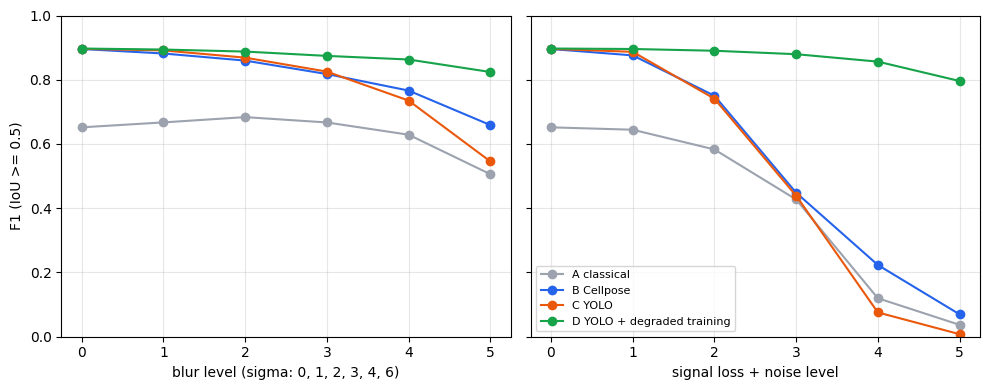

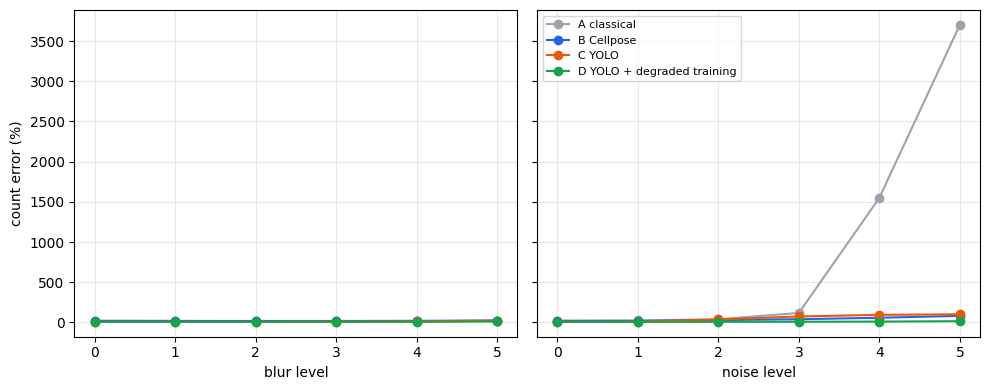

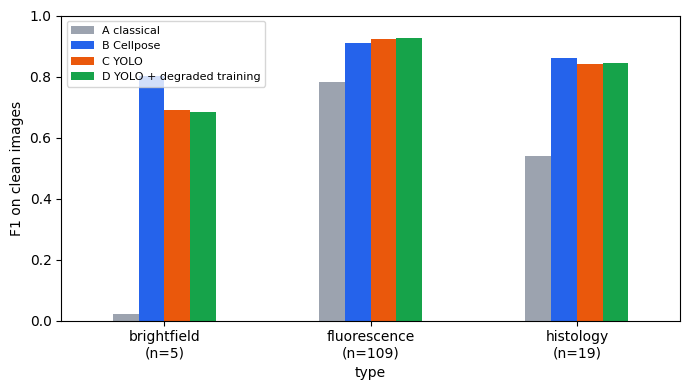

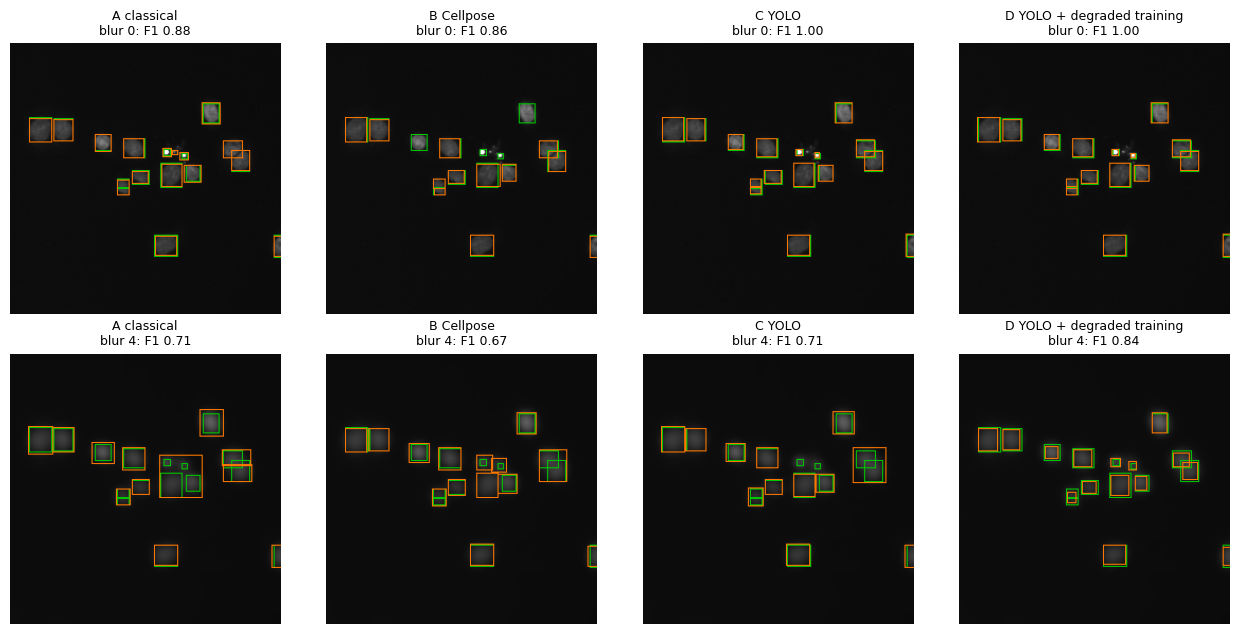

In [11]:
colors = {'A_classical': '#9CA3AF', 'B_cellpose': '#2563EB', 'C_yolo': '#EA580C', 'D_yolo_aug': '#16A34A'}

# 그림 1: 단계별 F1
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, kind, xlabel in zip(axes, ('blur', 'noise'), ('blur level (sigma: ' + ', '.join(map(str, BLUR)) + ')',
                                                      'signal loss + noise level')):
    for m in RUNNERS:
        t = table[(table.kind == kind) & (table.method == m)].sort_values('level')
        ax.plot(t.level, t.F1, 'o-', color=colors[m], label=METHOD_NAMES[m])
    ax.set_xlabel(xlabel); ax.set_xticks(LEVELS); ax.grid(alpha=.3)
axes[0].set_ylabel('F1 (IoU >= 0.5)'); axes[0].set_ylim(0, 1); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/1_f1_vs_degradation.png', dpi=150); plt.show()

# 그림 2: 단계별 개수 오차
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, kind in zip(axes, ('blur', 'noise')):
    for m in RUNNERS:
        t = table[(table.kind == kind) & (table.method == m)].sort_values('level')
        ax.plot(t.level, t.count_err * 100, 'o-', color=colors[m], label=METHOD_NAMES[m])
    ax.set_xlabel(f'{kind} level'); ax.set_xticks(LEVELS); ax.grid(alpha=.3)
axes[0].set_ylabel('count error (%)'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/2_count_error.png', dpi=150); plt.show()

# 그림 3: 원본 사진에서 사진 종류별 F1
by_type = df[df.level == 0].drop_duplicates(['method', 'id']).groupby(['type', 'method'])[['tp', 'fp', 'fn', 'n_pred', 'n_gt']].apply(summarize).F1.unstack()
by_type = by_type[list(RUNNERS)]
ax = by_type.plot.bar(figsize=(7, 4), color=[colors[m] for m in by_type.columns], rot=0)
ax.set_ylabel('F1 on clean images'); ax.set_ylim(0, 1); ax.legend([METHOD_NAMES[m] for m in by_type.columns], fontsize=8)
counts = df[(df.level == 0) & (df.method == 'A_classical')].drop_duplicates('id').type.value_counts()
ax.set_xticklabels([f'{t}\n(n={counts.get(t, 0)})' for t in by_type.index])
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/3_f1_by_image_type.png', dpi=150); plt.show()

# 그림 4: 같은 사진에서 원본과 흐림 4단계의 예측 비교 (초록: 정답, 주황: 예측)
ex = demo
fig, ax = plt.subplots(2, len(RUNNERS), figsize=(3.2 * len(RUNNERS), 6.4))
for row, lv in enumerate((0, 4)):
    img = degrade(load_img(ex), 'blur', lv, ex)
    for col, (m, run) in enumerate(RUNNERS.items()):
        pred = run([img])[0]; tp, fp, fn = match(pred, GT[ex])
        vis = img.copy()
        for x1, y1, x2, y2 in GT[ex].astype(int):
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 200, 0), 1)
        for x1, y1, x2, y2 in pred.astype(int):
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 120, 255), 1)
        f1 = 2 * tp / max(2 * tp + fp + fn, 1)
        ax[row, col].imshow(vis[..., ::-1]); ax[row, col].axis('off')
        ax[row, col].set_title(f'{METHOD_NAMES[m]}\nblur {lv}: F1 {f1:.2f}', fontsize=9)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/4_example_predictions.png', dpi=150); plt.show()

# 학습 곡선도 함께 모아 둡니다
for name in ('C_yolo', 'D_yolo_aug'):
    src = f'{ROOT}/runs/{name}/results.png'
    if os.path.exists(src):
        shutil.copy(src, f'{ROOT}/figures/5_learning_curve_{name}.png')

## 9. 지원서에 옮길 숫자

아래 문장은 결과에서 자동으로 만든 것입니다. 숫자를 확인한 뒤 본인 말로 바꿔 쓰세요. QUICK 모드에서 나온 숫자는 쓰지 마세요.

In [12]:
def f1(m, kind, lv):
    return table[(table.method == m) & (table.kind == kind) & (table.level == lv)].F1.item()

clean = {m: f1(m, 'blur', 0) for m in RUNNERS}
best_clean = max(clean, key=clean.get)
print(f'- 평가용 사진 {len(val_ids)}장(세포핵 {int(n_nuclei.sum())}개) 기준')
print('- 원본 사진 F1: ' + ', '.join(f'{METHOD_NAMES[m]} {v:.2f}' for m, v in clean.items()))
for kind in ('blur', 'noise'):
    drop = {m: clean[m] - f1(m, kind, 4) for m in RUNNERS}
    print(f'- {kind} 4단계 F1: ' + ', '.join(f'{METHOD_NAMES[m]} {f1(m, kind, 4):.2f}' for m in RUNNERS)
          + f'  (가장 크게 떨어진 방법: {METHOD_NAMES[max(drop, key=drop.get)]})')
for kind in ('blur', 'noise'):
    c, d = f1('C_yolo', kind, 4), f1('D_yolo_aug', kind, 4)
    print(f'- 흐린 사진을 섞어 학습(C → D): {kind} 4단계 F1 {c:.2f} → {d:.2f}, '
          f'원본 F1 {clean["C_yolo"]:.2f} → {clean["D_yolo_aug"]:.2f}')
if QUICK:
    print('\n(QUICK 모드 결과입니다. 지원서에 쓰지 마세요.)')

- 평가용 사진 133장(세포핵 5647개) 기준
- 원본 사진 F1: A classical 0.65, B Cellpose 0.90, C YOLO 0.90, D YOLO + degraded training 0.90
- blur 4단계 F1: A classical 0.63, B Cellpose 0.77, C YOLO 0.74, D YOLO + degraded training 0.86  (가장 크게 떨어진 방법: C YOLO)
- noise 4단계 F1: A classical 0.12, B Cellpose 0.22, C YOLO 0.08, D YOLO + degraded training 0.86  (가장 크게 떨어진 방법: C YOLO)
- 흐린 사진을 섞어 학습(C → D): blur 4단계 F1 0.74 → 0.86, 원본 F1 0.90 → 0.90
- 흐린 사진을 섞어 학습(C → D): noise 4단계 F1 0.08 → 0.86, 원본 F1 0.90 → 0.90


## 10. 기록과 공유

**꼭 남길 것** (나중에 다시 만들 수 없습니다)
- 에러 화면과 고친 방법, 처음 예상과 달랐던 결과 한 가지
- `figures` 폴더의 그림 1~4와 학습 곡선, `results/summary.csv`
- 결과를 보고 세운 가설 한 줄. 예: "흐림에서 A가 먼저 무너진 이유는 임계값이 경계를 못 잡아서일 것이다" → 그림 4로 확인

**GitHub에 올리기**: 파일 > GitHub에 사본 저장. README에는 질문, 데이터 출처, 네 방법, 그림 1, 한계를 적습니다.

**한계** (보고서와 면접에서 먼저 말하기)
- 흐림·잡음은 단순한 수학적 열화이며 실제 조직의 광학 산란과 다릅니다.
- 평가용 사진을 무작위로 나눠, 같은 실험에서 나온 비슷한 사진이 학습과 평가에 함께 들어갔을 수 있습니다. 점수가 실제보다 높게 나올 수 있습니다.
- 평가용 사진은 대부분 형광 사진이고 명시야 사진은 5장뿐이라, 그림 3의 종류별 비교는 참고용입니다.
- Cellpose는 추가 학습 없이 썼고 YOLO는 이 데이터로 학습했으므로, 원본 점수 비교는 공정한 경쟁이 아닙니다. 이 실험의 핵심은 순위보다 **흐려질 때 각 방법이 얼마나 떨어지는가**입니다.
- 상자(위치)만 채점했고 세포핵의 모양(경계)은 채점하지 않았습니다.
- 7번의 `noise`는 색 채널마다 따로 잡음을 넣어 흑백 사진에 색 얼룩이 생겼습니다. 흑백으로 바꿔 처리하는 A·B와 달리 C는 이 얼룩을 그대로 보므로, 잡음에서의 C와 B 비교는 조심해서 말해야 합니다(11번 `shot`으로 확인).

## 11. 추가 실험: 학습 때 보지 못한 열화

D는 시험에 쓴 것과 **같은 방식**(가우시안 흐림, 신호 약화 + 가우시안 잡음)으로 만든 사진을 보고 학습했습니다. 그래서 7번 실험만으로는 D가 "흐림 자체에 강해진 것"인지, "본 적 있는 흐림에만 강해진 것"인지 구분할 수 없습니다. 학습에 쓰지 않은 세 가지 열화로 확인합니다.

- `motion`: 한 방향으로 번지는 흐림 (시료나 카메라의 움직임)
- `shot`: 빛 알갱이가 적을 때 생기는 잡음 (밝은 곳일수록 커지는 푸아송 잡음)
- `lowres`: 해상도 저하 (작게 줄였다가 다시 키움)

7번의 `noise`는 색 채널마다 따로 잡음을 넣어서, 흑백 사진에 원래 없던 색 얼룩이 생겼습니다. A와 B는 사진을 흑백으로 바꾼 뒤 처리하므로 이 얼룩이 평균되어 약해지지만, YOLO(C)는 색 얼룩을 그대로 봅니다. 그래서 7번에서 C가 잡음에 가장 약했던 데에는 이 차이도 섞여 있을 수 있습니다. 여기의 `shot`은 흑백 사진이면 세 채널에 같은 잡음을 넣어 이 점도 함께 확인합니다.

방법 A는 빼고 B, C, D만 비교합니다. Cellpose를 포함해 GPU에서 약 15~25분 걸리고, 결과는 `results/sweep_unseen.csv`에 저장됩니다.

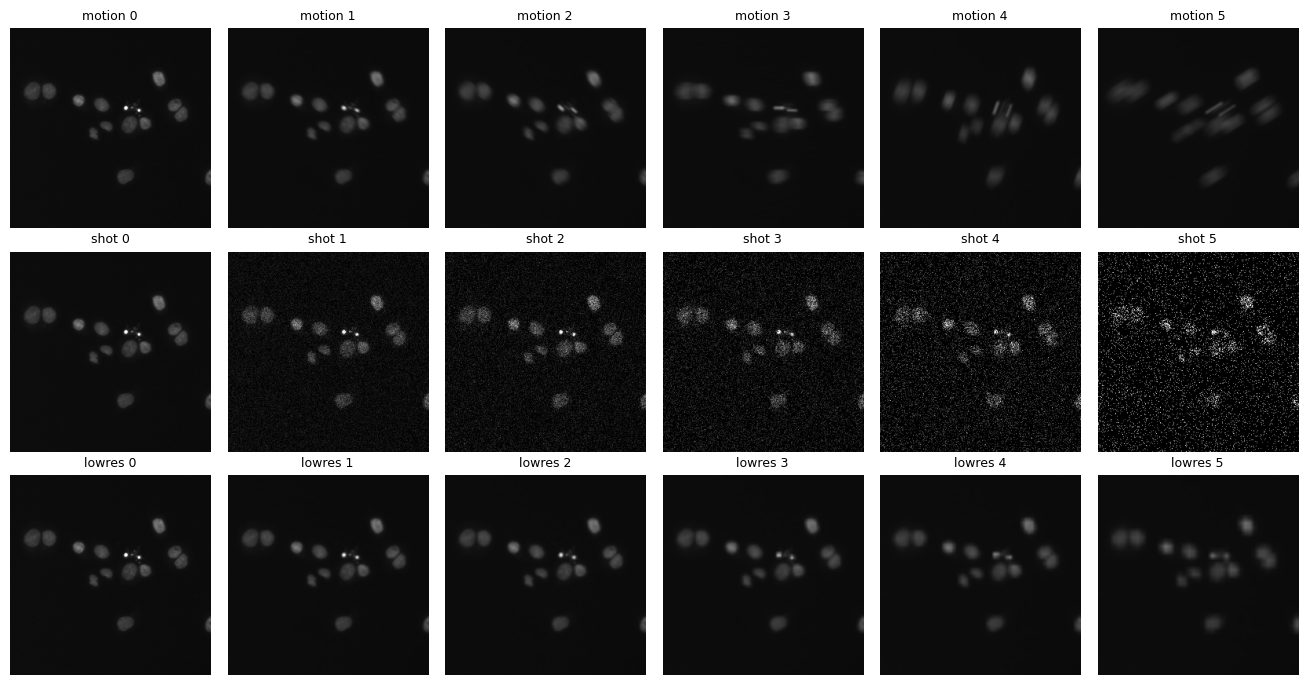

In [13]:
MOTION  = [0, 5, 9, 13, 17, 25]        # 번짐 길이 (픽셀)
PHOTONS = [None, 40, 20, 10, 5, 2]     # 가장 밝은 픽셀에 도착하는 빛 알갱이 수 (작을수록 거침)
SCALE   = [1, 1.5, 2, 3, 4, 6]         # 줄이는 배율
UNSEEN  = ('motion', 'shot', 'lowres')

def degrade_unseen(bgr, kind, level, key=''):
    if level == 0:
        return bgr
    rng = np.random.default_rng(int(hashlib.md5(f'{key}{kind}{level}'.encode()).hexdigest()[:8], 16))
    img = bgr.astype(np.float32)
    if kind == 'motion':
        n = MOTION[level]
        k = np.zeros((n, n), np.float32); k[n // 2, :] = 1
        rot = cv2.getRotationMatrix2D((n / 2 - .5, n / 2 - .5), float(rng.uniform(0, 180)), 1)
        k = cv2.warpAffine(k, rot, (n, n)); k /= max(k.sum(), 1e-6)
        img = cv2.filter2D(img, -1, k)
    elif kind == 'shot':
        peak = PHOTONS[level]
        is_gray = np.ptp(bgr.astype(np.int16), axis=2).max() == 0     # 세 채널이 같으면 흑백 사진
        src = img[..., :1] if is_gray else img                          # 흑백이면 세 채널에 같은 잡음
        noisy = rng.poisson(src / 255 * peak) / peak * 255
        img = np.repeat(noisy, 3, axis=2) if is_gray else noisy
    else:
        h, w = img.shape[:2]; sc = SCALE[level]
        small = cv2.resize(img, (max(1, round(w / sc)), max(1, round(h / sc))), interpolation=cv2.INTER_AREA)
        img = cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    return np.clip(img, 0, 255).astype(np.uint8)

fig, ax = plt.subplots(3, len(LEVELS), figsize=(2.2 * len(LEVELS), 6.9))
for row, kind in enumerate(UNSEEN):
    for col, lv in enumerate(LEVELS):
        ax[row, col].imshow(degrade_unseen(load_img(demo), kind, lv, demo)[..., ::-1]); ax[row, col].axis('off')
        ax[row, col].set_title(f'{kind} {lv}', fontsize=9)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/6_unseen_levels.png', dpi=150); plt.show()

motion 1 C YOLO 완료 (38초)
motion 1 D YOLO + degraded training 완료 (26초)
motion 2 C YOLO 완료 (28초)
motion 2 D YOLO + degraded training 완료 (28초)
motion 3 C YOLO 완료 (27초)
motion 3 D YOLO + degraded training 완료 (27초)
motion 4 C YOLO 완료 (27초)
motion 4 D YOLO + degraded training 완료 (27초)
motion 5 C YOLO 완료 (27초)
motion 5 D YOLO + degraded training 완료 (28초)
shot 1 C YOLO 완료 (28초)
shot 1 D YOLO + degraded training 완료 (29초)
shot 2 C YOLO 완료 (27초)
shot 2 D YOLO + degraded training 완료 (27초)
shot 3 C YOLO 완료 (29초)
shot 3 D YOLO + degraded training 완료 (29초)
shot 4 C YOLO 완료 (29초)
shot 4 D YOLO + degraded training 완료 (27초)
shot 5 C YOLO 완료 (29초)
shot 5 D YOLO + degraded training 완료 (29초)
lowres 1 C YOLO 완료 (28초)
lowres 1 D YOLO + degraded training 완료 (27초)
lowres 2 C YOLO 완료 (28초)
lowres 2 D YOLO + degraded training 완료 (28초)
lowres 3 C YOLO 완료 (28초)
lowres 3 D YOLO + degraded training 완료 (27초)
lowres 4 C YOLO 완료 (26초)
lowres 4 D YOLO + degraded training 완료 (27초)
lowres 5 C YOLO 완료 (27초)
lowres 5 D YOLO

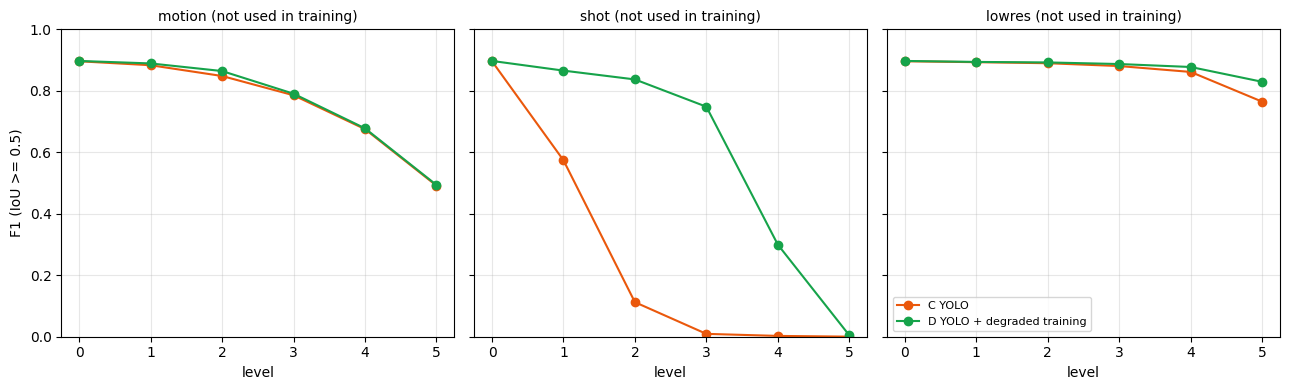

- motion 4단계 F1: C YOLO 0.68, D YOLO + degraded training 0.68
- shot 4단계 F1: C YOLO 0.00, D YOLO + degraded training 0.30
- lowres 4단계 F1: C YOLO 0.86, D YOLO + degraded training 0.88


method        C_yolo  D_yolo_aug
kind   level                    
lowres 0       0.896       0.897
       1       0.893       0.894
       2       0.890       0.892
       3       0.881       0.887
       4       0.861       0.877
       5       0.765       0.829
motion 0       0.896       0.897
       1       0.883       0.889
       2       0.848       0.864
       3       0.786       0.791
       4       0.675       0.678
       5       0.492       0.494
shot   0       0.896       0.897
       1       0.574       0.866
       2       0.112       0.837
       3       0.009       0.748
       4       0.003       0.300
       5       0.000       0.005

In [16]:
UNSEEN_WITH_CELLPOSE = False
methods_u = (('B_cellpose',) if UNSEEN_WITH_CELLPOSE else ()) + ('C_yolo', 'D_yolo_aug')
UNSEEN_RUNNERS = {m: RUNNERS[m] for m in methods_u if m in RUNNERS}
unseen_csv = f'{ROOT}/results/sweep_unseen.csv'
part_csv = f'{ROOT}/results/sweep_unseen_partial.csv'
import time

if os.path.exists(unseen_csv):
    du = pd.read_csv(unseen_csv)
    du = du[du.method.isin(UNSEEN_RUNNERS)]
else:
    done = pd.read_csv(part_csv) if os.path.exists(part_csv) else pd.DataFrame(columns=['method', 'kind', 'level'])
    originals = [load_img(i) for i in val_ids]
    for kind in UNSEEN:
        for lv in LEVELS[1:]:
            todo = [m for m in UNSEEN_RUNNERS
                    if not ((done.method == m) & (done.kind == kind) & (done.level == lv)).any()]
            if not todo:
                continue
            imgs = [degrade_unseen(im, kind, lv, i) for im, i in zip(originals, val_ids)]
            for m in todo:
                t0, rows = time.time(), []
                for i, p in zip(val_ids, UNSEEN_RUNNERS[m](imgs)):
                    tp, fp, fn = match(p, GT[i])
                    rows.append(dict(method=m, kind=kind, level=lv, id=i, type=TYPE[i],
                                     tp=tp, fp=fp, fn=fn, n_pred=len(p), n_gt=len(GT[i])))
                done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
                done.to_csv(part_csv, index=False)            # 단계마다 저장
                print(f'{kind} {lv} {METHOD_NAMES[m]} 완료 ({time.time() - t0:.0f}초)')
    clean = df[df.level == 0].drop_duplicates(['method', 'id'])      # 0단계는 7번 결과를 그대로 씀
    clean = clean[clean.method.isin(UNSEEN_RUNNERS)]
    du = pd.concat([clean.assign(kind=k) for k in UNSEEN] + [done[done.method.isin(UNSEEN_RUNNERS)]],
                   ignore_index=True)
    du.to_csv(unseen_csv, index=False)

table_u = du.groupby(['kind', 'level', 'method'])[['tp', 'fp', 'fn', 'n_pred', 'n_gt']].apply(summarize).reset_index()
table_u.to_csv(f'{ROOT}/results/summary_unseen.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, kind in zip(axes, UNSEEN):
    for m in UNSEEN_RUNNERS:
        t = table_u[(table_u.kind == kind) & (table_u.method == m)].sort_values('level')
        ax.plot(t.level, t.F1, 'o-', color=colors[m], label=METHOD_NAMES[m])
    ax.set_title(f'{kind} (not used in training)', fontsize=10); ax.set_xlabel('level')
    ax.set_xticks(LEVELS); ax.grid(alpha=.3)
axes[0].set_ylabel('F1 (IoU >= 0.5)'); axes[0].set_ylim(0, 1); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/7_f1_unseen_degradation.png', dpi=150); plt.show()

for kind in UNSEEN:
    line = ', '.join(f"{METHOD_NAMES[m]} {table_u[(table_u.method == m) & (table_u.kind == kind) & (table_u.level == 4)].F1.item():.2f}"
                     for m in UNSEEN_RUNNERS)
    print(f'- {kind} 4단계 F1: {line}')
table_u.pivot_table(index=['kind', 'level'], columns='method', values='F1').round(3)